# Réseaux sociaux : quels contenus engagent le plus ?

**Problème :** Comparer les vues et l'engagement par plateforme et type de publication. Anomalies : likes supérieurs aux vues, texte mal formaté.

Les données sont synthétiques. Exécute les cellules dans l'ordre. Le fichier `donnees.xlsx` doit rester dans le même dossier que ce notebook.

## Étape 1 — Lire et explorer les données

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_excel("donnees.xlsx", sheet_name="donnees")
print("Dimensions :", df.shape)
display(df.head())
display(df.sample(min(5, len(df)),random_state=1 ))


Dimensions : (30, 6)


,date,plateforme,publication,vues,likes,commentaires
0,2026-04-01,LinkedIn,Conseil,2391,418,74
1,2026-04-02,Instagram,Conseil,1766,197,42
2,2026-04-03,TikTok,Projet,1503,245,47
3,2026-04-04,LinkedIn,Conseil,1634,130,45
4,2026-04-05,TikTok,Projet,2627,481,12


,date,plateforme,publication,vues,likes,commentaires
17,2026-04-18,TikTok,Question,2960,90,11
21,2026-04-22,TikTok,Projet,1602,68,44
10,2026-04-11,LinkedIn,Conseil,3907,182,47
19,2026-04-20,TikTok,Conseil,2228,480,31
14,2026-04-15,TikTok,Question,4716,330,51


## Étape 2 — Comprendre la structure

In [2]:
df.info()
display(df.describe(include="all").T)
print("Colonnes :", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          30 non-null     datetime64[us]
 1   plateforme    30 non-null     str           
 2   publication   30 non-null     str           
 3   vues          30 non-null     int64         
 4   likes         30 non-null     int64         
 5   commentaires  30 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(2)
memory usage: 1.5 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,30,NaN,NaN,NaN,2026-04-15 12:00:00,2026-04-01 00:00:00,2026-04-08 06:00:00,2026-04-15 12:00:00,2026-04-22 18:00:00,2026-04-30 00:00:00,NaN
plateforme,30,4,TikTok,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
publication,30,4,Projet,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vues,30.0,NaN,NaN,NaN,2569.766667,558.0,1634.5,2302.0,3760.75,4970.0,1311.863525
likes,30.0,NaN,NaN,NaN,441.833333,19.0,114.25,189.5,325.5,7000.0,1246.408138
commentaires,30.0,NaN,NaN,NaN,39.733333,3.0,22.5,44.5,51.0,74.0,19.949822


Colonnes : ['date', 'plateforme', 'publication', 'vues', 'likes', 'commentaires']


## Étape 3 — Détecter les anomalies

In [3]:
print("Valeurs manquantes :")
display(df.isna().sum())
print("Lignes dupliquées :", df.duplicated().sum())
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\\n{col} :", df[col].dropna().astype(str).unique()[:15])


Valeurs manquantes :


date            0
plateforme      0
publication     0
vues            0
likes           0
commentaires    0
dtype: int64

Lignes dupliquées : 0
\nplateforme : <StringArray>
['LinkedIn', 'Instagram', 'TikTok', ' instagram ']
Length: 4, dtype: str
\npublication : <StringArray>
['Conseil', 'Projet', 'Question', 'Tutoriel']
Length: 4, dtype: str


## Étape 4 — Nettoyer les données

On conserve `df` intact et on travaille sur une copie `df_clean`. Adapte les règles selon le problème métier.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

# Nettoyage simple des espaces dans les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

df_clean["plateforme"] = df_clean["plateforme"].str.title()
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.head())

Dimensions après nettoyage : (30, 6)


,date,plateforme,publication,vues,likes,commentaires
0,2026-04-01,Linkedin,Conseil,2391,418,74
1,2026-04-02,Instagram,Conseil,1766,197,42
2,2026-04-03,Tiktok,Projet,1503,245,47
3,2026-04-04,Linkedin,Conseil,1634,130,45
4,2026-04-05,Tiktok,Projet,2627,481,12


## Étape 5 — Analyse avec Pandas et calculs NumPy

In [5]:
for col in ["vues","likes","commentaires"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_analyse = df_clean[(df_clean["vues"] >= 0) & (df_clean["likes"] >= 0) & (df_clean["commentaires"] >= 0)].copy()
df_analyse["taux_likes_pct"] = np.where(df_analyse["vues"] > 0, df_analyse["likes"] / df_analyse["vues"] * 100, np.nan)
display(df_analyse.groupby("plateforme")[["vues","likes","commentaires","taux_likes_pct"]].mean().round(2))


,vues,likes,commentaires,taux_likes_pct
plateforme,,,,
Instagram,2775.50,162.50,36.50,6.59
Linkedin,2557.60,281.00,53.00,14.45
Tiktok,2525.94,612.19,32.25,56.70


## Étape 6 — Visualisation avec Matplotlib

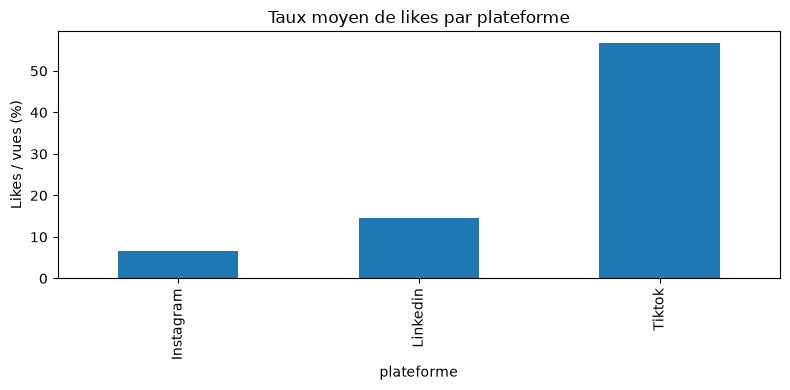

In [6]:
df_analyse.groupby("plateforme")["taux_likes_pct"].mean().sort_values().plot(kind="bar", figsize=(8,4))
plt.title("Taux moyen de likes par plateforme")
plt.ylabel("Likes / vues (%)")
plt.tight_layout()
plt.show()


## Exporter le résultat nettoyé

In [ ]:
df_clean.to_csv("donnees_nettoyees.csv", index=False, encoding="utf-8-sig")
df_clean.to_excel("donnees_nettoyees.xlsx", index=False)
print("Export terminé.")


Export terminé.
